# Vehicle Recognition Model Lab


We will build two CNNs, compare two ImageNet-pretrained architectures before and after adaptation, and investigate errors. We finish with a sequence-learning RNN.

**Learning objectives:** interpret images and transforms; trace CNN shapes and parameters; build and compare architectures; understand optimization, learning rate, overfitting and underfitting; distinguish zero-shot transfer, frozen feature extraction and fine-tuning; evaluate models fairly; explain the role of recurrent networks.

**Dataset choice:** CIFAR-100 contains six transport categories used here: `bicycle`, `bus`, `motorcycle`, `pickup_truck`, `train`, `streetcar`. This is a **vehicle-type classification** task, not individual car identification. The images are only 32×32; the optional plate project would require a different dataset and pipeline.

**References:** [CIFAR](https://www.cs.toronto.edu/~kriz/cifar.html) · [Torchvision CIFAR100](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR100.html) · [PyTorch transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) · [Torchvision models](https://docs.pytorch.org/vision/stable/models.html).

## Setup and reproducibility

The seed helps reproducibility, but GPU kernels and Colab hardware can still cause small variations. `FAST_MODE` keeps the first run practical. Increase sample sizes or epochs after you have a working baseline.

In [8]:
import copy, random, time, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageFilter
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| PyTorch:', torch.__version__)
FAST_MODE = True
TRAIN_PER_CLASS = 300 if FAST_MODE else 450
VAL_PER_CLASS = 80 if FAST_MODE else 50
BATCH_SIZE = 64
SCRATCH_EPOCHS = 4 if FAST_MODE else 8
HEAD_EPOCHS = 2 if FAST_MODE else 4
FINETUNE_EPOCHS = 2 if FAST_MODE else 4
NUM_WORKERS = 2

Device: cuda | PyTorch: 2.11.0+cu130


## 1. Inspect the images before training

An RGB image has height, width and three color channels. NumPy typically represents it as `[H, W, C]`, while PyTorch convolution expects `[N, C, H, W]` for a batch. The separate red/green/blue visualizations are *intensity maps*, not new RGB photographs.

**Investigation:** Why might a classifier struggle to distinguish a bus from a streetcar in a 32×32 image? Does resizing create missing detail?

In [9]:
import torchvision.datasets as datasets
# تعيين رابط المرآة البديل لتنزيل مجموعة بيانات CIFAR-100 لتفادي مشاكل الاتصال
datasets.CIFAR100.url = 'https://data.brainchip.com/dataset-mirror/cifar100/cifar-100-python.tar.gz'

Selected categories: ['bicycle', 'bus', 'motorcycle', 'pickup_truck', 'train', 'streetcar']


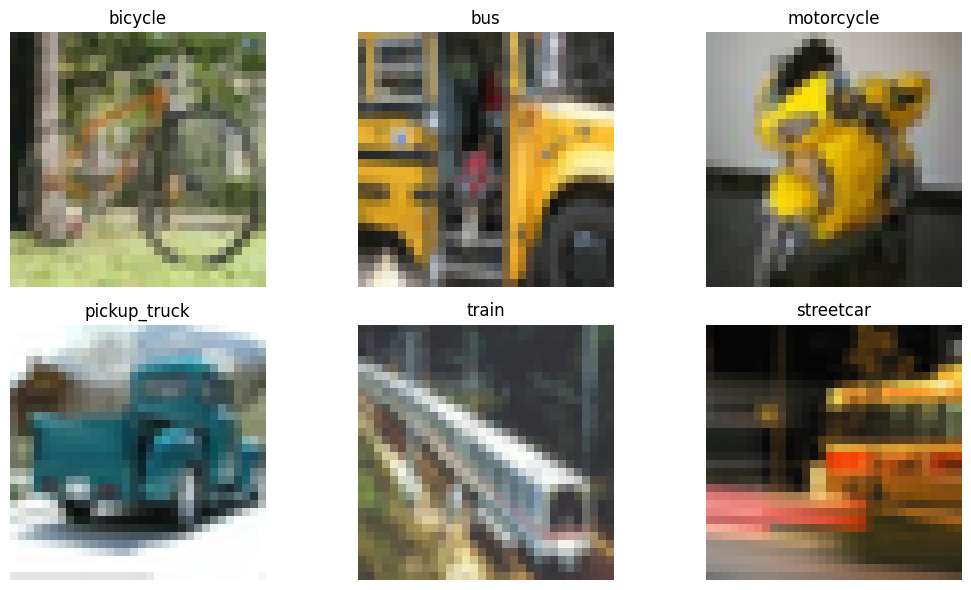

NumPy HWC: (32, 32, 3) pixel [0,0]: [185 151  71]


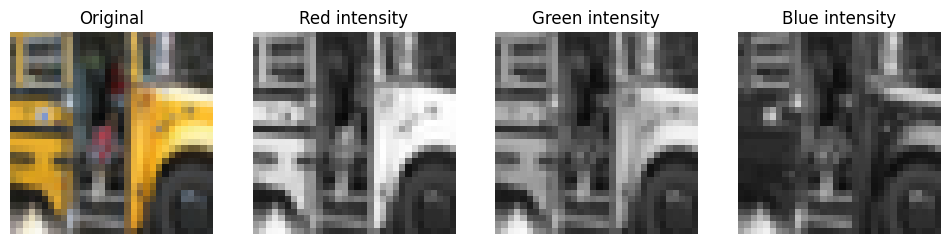

In [10]:
raw_train = datasets.CIFAR100(root='./data', train=True, download=True)
raw_test = datasets.CIFAR100(root='./data', train=False, download=True)
CLASS_NAMES = ['bicycle', 'bus', 'motorcycle', 'pickup_truck', 'train', 'streetcar']
CLASS_IDS = [raw_train.classes.index(x) for x in CLASS_NAMES]
print('Selected categories:', CLASS_NAMES)
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, name, original_id in zip(axes.flat, CLASS_NAMES, CLASS_IDS):
    idx = next(i for i, label in enumerate(raw_train.targets) if label == original_id)
    image, _ = raw_train[idx]
    ax.imshow(image, interpolation='nearest'); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()
image, _ = raw_train[next(i for i, y in enumerate(raw_train.targets) if y == CLASS_IDS[1])]
arr = np.asarray(image)
print('NumPy HWC:', arr.shape, 'pixel [0,0]:', arr[0,0])
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(image, interpolation='nearest'); axes[0].set_title('Original')
for channel, name in enumerate(['Red','Green','Blue']):
    axes[channel+1].imshow(arr[:,:,channel], cmap='gray', vmin=0, vmax=255)
    axes[channel+1].set_title(name+' intensity')
for ax in axes: ax.axis('off')
plt.show()

### Transformations: what changes and what stays the same?

`ToTensor()` converts typical 8-bit PIL RGB images into floating-point tensors in `[0,1]`, rearranging channels to `[C,H,W]`. Normalization then subtracts a mean and divides by a standard deviation per channel. ImageNet-pretrained weights have prescribed preprocessing; applying the wrong normalization can reduce performance.

**Try:** compare nearest-neighbor and bilinear enlargement. Then explain why neither reveals license-plate characters absent from the original image.

PIL size: (32, 32) | tensor shape: (3, 32, 32) | range: (0.027450980618596077, 1.0)


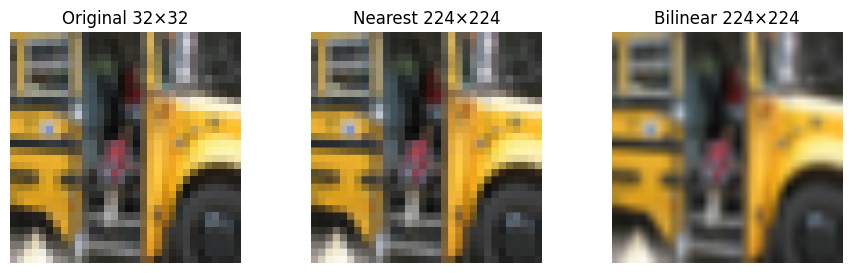

In [11]:
tensor = transforms.ToTensor()(image)
print('PIL size:', image.size, '| tensor shape:', tuple(tensor.shape), '| range:', (tensor.min().item(), tensor.max().item()))
fig, axes = plt.subplots(1,3,figsize=(11,3))
axes[0].imshow(image); axes[0].set_title('Original 32×32')
axes[1].imshow(image.resize((224,224), Image.Resampling.NEAREST)); axes[1].set_title('Nearest 224×224')
axes[2].imshow(image.resize((224,224), Image.Resampling.BILINEAR)); axes[2].set_title('Bilinear 224×224')
for ax in axes: ax.axis('off')
plt.show()

## 2. Prepare a fair dataset split

All four architectures must use identical examples. We select a reproducible subset of the training set and reserve validation images for model selection. The **test set remains untouched until the final comparison**. Pretrained CNNs use 160×160 resized images with ImageNet normalization; scratch CNNs use 32×32 images. This difference is necessary for pretrained backbones but is a limitation when interpreting comparisons.

Augmentation is used only for training. A horizontal flip is reasonable for vehicle type, but not for recognizing license-plate text.

In [12]:
rng = np.random.default_rng(SEED)
train_ids, val_ids = [], []
for old_id in CLASS_IDS:
    candidates = np.where(np.asarray(raw_train.targets) == old_id)[0]
    candidates = rng.permutation(candidates)
    train_ids.extend(candidates[:TRAIN_PER_CLASS]); val_ids.extend(candidates[TRAIN_PER_CLASS:TRAIN_PER_CLASS+VAL_PER_CLASS])
test_ids = [i for i, y in enumerate(raw_test.targets) if y in CLASS_IDS]
label_map = {old:new for new,old in enumerate(CLASS_IDS)}
class SelectedVehicles(Dataset):
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, list(indices), transform
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        im, old_label = self.base[self.indices[i]]
        return self.transform(im), label_map[old_label]

scratch_train_tf = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.ToTensor(), transforms.Normalize((.5,)*3,(.5,)*3)])
scratch_eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((.5,)*3,(.5,)*3)])
# Standard ImageNet statistics, appropriate for these pretrained torchvision weights.
IMAGENET_MEAN = (0.485,0.456,0.406); IMAGENET_STD=(0.229,0.224,0.225)
pre_train_tf = transforms.Compose([transforms.Resize((160,160)), transforms.RandomHorizontalFlip(), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
pre_eval_tf = transforms.Compose([transforms.Resize((160,160)), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

def make_loaders(train_tf, eval_tf):
    return (DataLoader(SelectedVehicles(raw_train,train_ids,train_tf),batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=device.type=='cuda'),
            DataLoader(SelectedVehicles(raw_train,val_ids,eval_tf),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=device.type=='cuda'),
            DataLoader(SelectedVehicles(raw_test,test_ids,eval_tf),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=device.type=='cuda'))
s_train,s_val,s_test = make_loaders(scratch_train_tf,scratch_eval_tf)
p_train,p_val,p_test = make_loaders(pre_train_tf,pre_eval_tf)
print('Train:',len(train_ids),'Validation:',len(val_ids),'Test:',len(test_ids))

Train: 1800 Validation: 480 Test: 600


## 3. How does a CNN actually work?

A CNN processes a batch of images through a sequence of operations:

- **Convolution (`Conv2d`)** learns local patterns. `in_channels` must match the previous layer; `out_channels` is the number of learned filters. For a 3×3 filter, stride 1, padding 1, height and width stay unchanged.
- **ReLU** sets negative activations to zero, introducing nonlinearity.
- **Max pooling** retains the strongest activation in each local window, usually reducing spatial dimensions by half.
- **Batch normalization** stabilizes activation distributions during training; it also has learned scale and shift parameters.
- **Dropout** randomly suppresses activations *during training* to reduce reliance on individual features; it is disabled in evaluation mode.
- **Global average pooling** reduces each feature map to one number, avoiding a very large flattened classifier.
- **Linear layer** combines learned features into one score (logit) per vehicle category. `CrossEntropyLoss` takes logits directly; do not apply softmax before the loss.

For convolution, output width is `floor((W + 2P − D(K−1) − 1)/S + 1)`. Parameters (with bias) are `out_channels × (in_channels × K × K + 1)`.

**Example:** input `[N,3,32,32]` → Conv(3→16, 3×3, padding 1) `[N,16,32,32]` → MaxPool(2) `[N,16,16,16]`.

**Before running:** calculate the parameter count of the first convolution. Then verify it in code.

In [13]:
example_conv = nn.Conv2d(3,16,kernel_size=3,padding=1)
print('Conv parameters:',sum(p.numel() for p in example_conv.parameters()), '(expected 16×(3×3×3+1)=448)')
x_demo = torch.randn(2,3,32,32)
print('Input:',tuple(x_demo.shape),'Conv:',tuple(example_conv(x_demo).shape),'Pool:',tuple(nn.MaxPool2d(2)(example_conv(x_demo)).shape))

Conv parameters: 448 (expected 16×(3×3×3+1)=448)
Input: (2, 3, 32, 32) Conv: (2, 16, 32, 32) Pool: (2, 16, 16, 16)


### Architecture A — Compact CNN

A simple baseline with two convolutional stages. The feature maps grow from 16 to 32 channels, while pooling reduces spatial resolution. Adaptive pooling ensures the final classifier does not depend on a particular flattened spatial size.

**Architecture:** `[3,32,32] → Conv16 → ReLU → Pool → Conv32 → ReLU → Pool → AdaptiveAvgPool → Linear(6)`.

### Architecture B — Deeper regularized CNN

Three blocks use two convolutions each, batch normalization and dropout. This model has greater representational capacity but may overfit on a small dataset.

**Architecture:** `Conv32×2 → Pool → Conv64×2 → Pool → Conv128×2 → Pool → AdaptiveAvgPool → Dropout → Linear(6)`.

**Hypothesis:** which architecture will achieve higher validation accuracy, and why?

In [14]:
class CompactCNN(nn.Module):
    def __init__(self, n_classes=6):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(3,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1))
        self.classifier=nn.Linear(32,n_classes)
    def forward(self,x): return self.classifier(self.features(x).flatten(1))

class DeepCNN(nn.Module):
    def __init__(self,n_classes=6):
        super().__init__()
        blocks=[]
        prev=3
        for width in [32,64,128]:
            blocks.extend([nn.Conv2d(prev,width,3,padding=1,bias=False),nn.BatchNorm2d(width),nn.ReLU(),
                           nn.Conv2d(width,width,3,padding=1,bias=False),nn.BatchNorm2d(width),nn.ReLU(),
                           nn.MaxPool2d(2)])
            prev=width
        self.features=nn.Sequential(*blocks,nn.AdaptiveAvgPool2d(1))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Dropout(.3),nn.Linear(128,n_classes))
    def forward(self,x): return self.classifier(self.features(x))

for cls in [CompactCNN,DeepCNN]:
    net=cls()
    print(cls.__name__, 'parameters:',sum(p.numel() for p in net.parameters()),'output:',tuple(net(torch.randn(2,3,32,32)).shape))

CompactCNN parameters: 5286 output: (2, 6)
DeepCNN parameters: 288230 output: (2, 6)


### Train/evaluate helper: understand each step

Training is not just calling `model(x)`. For each batch we: clear old gradients, compute logits, measure cross-entropy, backpropagate, and update parameters. Validation runs under `no_grad()` and `eval()` so dropout/batch normalization behave correctly. We save the checkpoint with the **best validation accuracy**, not the last epoch.

The code below also records losses and accuracy so that students can diagnose underfitting or overfitting.

In [15]:
def evaluate(model,loader,return_predictions=False):
    model.eval(); criterion=nn.CrossEntropyLoss()
    loss_total=0.; correct=0; total=0; all_true=[]; all_pred=[]
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            logits=model(x); loss=criterion(logits,y)
            loss_total+=loss.item()*len(y)
            predictions=logits.argmax(1)
            correct+=(predictions==y).sum().item(); total+=len(y)
            if return_predictions:
                all_true.extend(y.cpu().tolist());all_pred.extend(predictions.cpu().tolist())
    result={'loss':loss_total/total,'accuracy':correct/total}
    return (result,all_true,all_pred) if return_predictions else result

def fit(model,train_loader,val_loader,epochs=4,lr=1e-3,trainable_only=False):
    model.to(device)
    params=[p for p in model.parameters() if p.requires_grad] if trainable_only else model.parameters()
    optimizer=torch.optim.Adam(params,lr=lr)
    criterion=nn.CrossEntropyLoss()
    history=[]; best_acc=-1; best_state=None
    started=time.perf_counter()
    for epoch in range(epochs):
        model.train(); total_loss=0; correct=0; total=0
        for x,y in train_loader:
            x,y=x.to(device),y.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits=model(x);loss=criterion(logits,y)
            loss.backward();optimizer.step()
            total_loss+=loss.item()*len(y)
            correct+=(logits.argmax(1)==y).sum().item();total+=len(y)
        validation=evaluate(model,val_loader)
        history.append({'epoch':epoch+1,'train_loss':total_loss/total,'train_accuracy':correct/total,
                        'val_loss':validation['loss'],'val_accuracy':validation['accuracy']})
        print(f'Epoch {epoch+1}/{epochs}: train acc {correct/total:.3f}, val acc {validation["accuracy"]:.3f}, val loss {validation["loss"]:.3f}')
        if validation['accuracy']>best_acc:
            best_acc=validation['accuracy'];best_state=copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return history,time.perf_counter()-started

def plot_history(history,title):
    df=pd.DataFrame(history)
    fig,axes=plt.subplots(1,2,figsize=(11,3))
    axes[0].plot(df.epoch,df.train_loss,label='Train');axes[0].plot(df.epoch,df.val_loss,label='Validation');axes[0].set_title(title+' loss')
    axes[1].plot(df.epoch,df.train_accuracy,label='Train');axes[1].plot(df.epoch,df.val_accuracy,label='Validation');axes[1].set_title(title+' accuracy')
    for ax in axes: ax.set_xlabel('Epoch');ax.legend();ax.grid(alpha=.2)
    plt.tight_layout();plt.show()

results=[]; trained={}
def record(name,stage,model,loader,seconds=0):
    score=evaluate(model,loader)
    results.append({'model':name,'stage':stage,'val_accuracy':score['accuracy'],'val_loss':score['loss'],
                    'parameters':sum(p.numel() for p in model.parameters()),'train_seconds':round(seconds,1)})
    print(name,stage,'validation accuracy:',f'{score["accuracy"]:.1%}')

## 4. Learning to train a network: loss, gradients and optimization

So far we have built two CNNs, but **building a network is not the same as teaching it**. A model begins with mostly random weights. During training it must discover which weights make its predictions more accurate.

The training cycle is:

1. **Forward pass:** the image passes through the network, producing six *logits* (unnormalized class scores).
2. **Loss function:** `CrossEntropyLoss` compares the logits with the correct class. A smaller loss generally means the predictions fit the labels better.
3. **Backpropagation:** `loss.backward()` uses the chain rule to calculate how each trainable weight contributes to the loss. It computes gradients but **does not update the weights**.
4. **Optimizer step:** `optimizer.step()` uses those gradients to update the weights.
5. **Reset gradients:** `optimizer.zero_grad()` prevents gradients from accumulating unintentionally between batches.

**Gradient descent intuition:** imagine walking downhill in fog. The gradient tells you which direction is uphill; the optimizer takes a step in the opposite direction. The **learning rate** controls the step size. Too small may learn slowly; too large may jump past a good solution or become unstable.

**Mini-batch:** instead of calculating gradients from every training image at once, we process a small batch (64 here). One **epoch** means processing all training batches once. One **iteration/step** is one optimizer update on one batch.

**Adam vs SGD:** SGD updates parameters using gradients (optionally with momentum). Adam adapts update sizes using moving estimates of first and second gradient moments. Neither is guaranteed to be best for every task. We use Adam for the main experiment and explore SGD below.

Read the next code cell carefully: it exposes the training operations that the later `fit()` helper performs automatically.

In [16]:
# One transparent optimization step on real vehicle images.
small_model = CompactCNN().to(device)
images, labels = next(iter(s_train))
images, labels = images.to(device), labels.to(device)
criterion = nn.CrossEntropyLoss()
optimizer_demo = torch.optim.SGD(small_model.parameters(), lr=0.01)

small_model.train()
optimizer_demo.zero_grad(set_to_none=True)
logits = small_model(images)                 # forward pass: [batch, 6]
loss = criterion(logits, labels)             # scalar cross-entropy loss
weight_before = small_model.features[0].weight.detach().clone()
loss.backward()                              # compute gradients
first_gradient = small_model.features[0].weight.grad
print('Batch images:', tuple(images.shape), '| logits:', tuple(logits.shape))
print('Loss:', round(loss.item(), 4))
print('Mean absolute gradient:', first_gradient.abs().mean().item())
optimizer_demo.step()                        # update parameters
weight_after = small_model.features[0].weight.detach()
print('Mean absolute weight change:', (weight_after-weight_before).abs().mean().item())


Batch images: (64, 3, 32, 32) | logits: (64, 6)
Loss: 1.7985
Mean absolute gradient: 0.0013258521212264895
Mean absolute weight change: 1.3258378203317989e-05


### How do we know whether the model is learning the right patterns?

A model should not only remember its training examples; it should perform well on **unseen images**. This is called *generalization*.

- **Underfitting:** the model has not learned enough useful patterns. Training and validation performance are both poor. Causes may include insufficient capacity, too few training epochs, unsuitable preprocessing, or an inappropriate learning rate.
- **Overfitting:** the model learns training-specific details that do not generalize. Training loss keeps decreasing while validation loss rises, or training accuracy is much higher than validation accuracy.
- **Good fit:** training and validation metrics improve together and remain reasonably close. A small gap is normal.

Training accuracy alone cannot tell us whether the model generalizes. **Validation data** guides architecture and hyperparameter choices; the **test set** is reserved for final evaluation.

A rising validation loss does not necessarily mean validation accuracy must immediately fall: accuracy counts correct classes, while cross-entropy also responds to the model's confidence.

**Check your understanding:** A model gets 98% training accuracy but 51% validation accuracy. Is this evidence of overfitting or underfitting? What extra evidence would you examine?

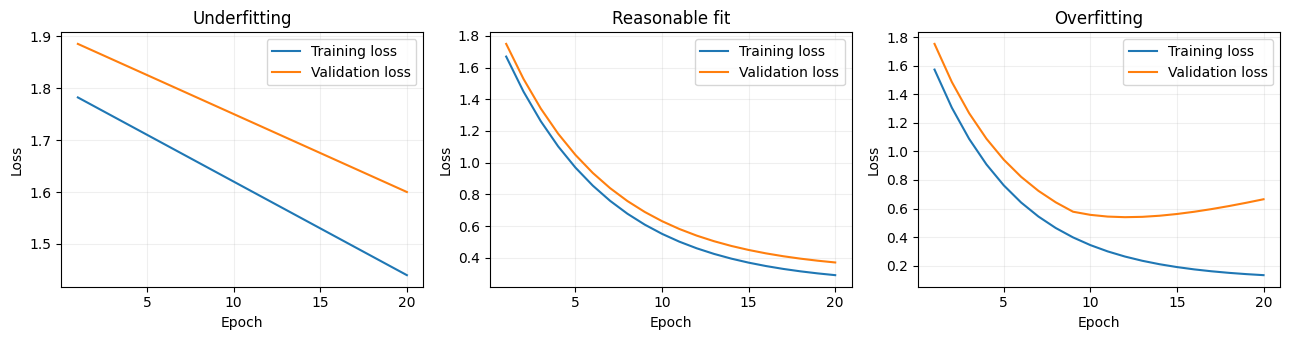

These are conceptual examples; your real curves will differ.


In [18]:
# These curves are illustrations, not measured results from our vehicle dataset.
epoch_axis = np.arange(1, 21)
under_train = 1.8 - 0.018 * epoch_axis
under_val = 1.9 - 0.015 * epoch_axis
fit_train = 1.7 * np.exp(-epoch_axis/6) + 0.23
fit_val = 1.7 * np.exp(-epoch_axis/6) + 0.31
ov_train = 1.8 * np.exp(-epoch_axis/5) + 0.10
ov_val = 1.8 * np.exp(-epoch_axis/5) + 0.28 + 0.032 * np.maximum(epoch_axis-9,0)
fig, axes = plt.subplots(1,3,figsize=(13,3.5))
for ax, title, tr, va in zip(axes, ['Underfitting','Reasonable fit','Overfitting'],
                             [under_train,fit_train,ov_train],[under_val,fit_val,ov_val]):
    ax.plot(epoch_axis,tr,label='Training loss'); ax.plot(epoch_axis,va,label='Validation loss')
    ax.set(title=title,xlabel='Epoch',ylabel='Loss'); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
print('These are conceptual examples; your real curves will differ.')

### How can we reduce overfitting?

We will investigate several techniques and their trade-offs:

| Technique | What it changes | When it might help |
|---|---|---|
| **Data augmentation** | Randomly alters training images (e.g., horizontal flips) without changing their labels | More varied training examples; less reliance on exact image positions |
| **Dropout** | Temporarily sets some activations to zero during training | Reduces reliance on specific features |
| **Weight decay** | Penalizes large weights through the optimizer | Encourages simpler parameter values |
| **Early stopping** | Stops when validation performance stops improving | Avoids excessive training after generalization deteriorates |
| **More data** | Provides more examples of genuine variation | Often helps models generalize |
| **Simpler model** | Reduces model capacity | May help when the dataset is small |

**Important:** These are not interchangeable. Too much dropout or weight decay can cause underfitting. Augmentations must preserve the label: flipping a bus is usually fine for vehicle classification, but flipping license-plate text changes the characters.

**Batch normalization** helps stabilize training and can sometimes regularize, but its primary role is not the same as dropout.

In the main experiment, Compact CNN has fewer layers and Deep CNN has more layers plus batch normalization and dropout. Compare their *validation* curves rather than assuming the deeper model will always win.

### Guided experiment: deliberately create overfitting

A small training set makes it easier to see the difference between memorization and generalization. Train the deeper CNN on a **tiny subset** of the existing training images, but evaluate it on the original validation set.

The code is intentionally separated from the main model competition: it does not overwrite `trained` or `results`. Start with the default settings. Then try one change at a time: increase epochs, increase weight decay, or reduce dropout by editing the model architecture above.

**Write down:** Which curve starts diverging first? Does higher training accuracy guarantee higher validation accuracy? Why is this experiment different from our fair four-model comparison?

Epoch 1/18: train acc 0.233, val acc 0.167, val loss 1.794
Epoch 2/18: train acc 0.467, val acc 0.167, val loss 1.854
Epoch 3/18: train acc 0.567, val acc 0.167, val loss 2.105
Epoch 4/18: train acc 0.708, val acc 0.167, val loss 2.376
Epoch 5/18: train acc 0.667, val acc 0.194, val loss 2.947
Epoch 6/18: train acc 0.800, val acc 0.173, val loss 2.720
Epoch 7/18: train acc 0.783, val acc 0.185, val loss 2.757
Epoch 8/18: train acc 0.808, val acc 0.196, val loss 2.534
Epoch 9/18: train acc 0.850, val acc 0.348, val loss 1.850
Epoch 10/18: train acc 0.942, val acc 0.362, val loss 1.942
Epoch 11/18: train acc 0.942, val acc 0.271, val loss 2.450
Epoch 12/18: train acc 0.925, val acc 0.333, val loss 2.008
Epoch 13/18: train acc 0.967, val acc 0.371, val loss 1.913
Epoch 14/18: train acc 0.975, val acc 0.310, val loss 2.329
Epoch 15/18: train acc 0.983, val acc 0.392, val loss 1.702
Epoch 16/18: train acc 0.992, val acc 0.375, val loss 1.745
Epoch 17/18: train acc 0.992, val acc 0.327, val 

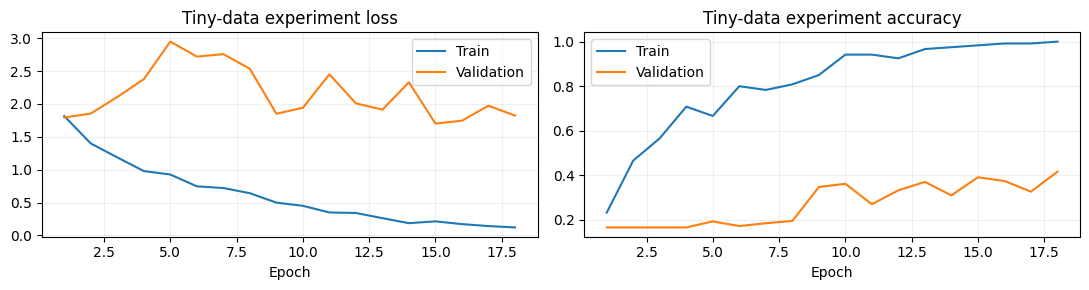

Last epoch metrics: {'epoch': 18, 'train_loss': 0.12232510397831599, 'train_accuracy': 1.0, 'val_loss': 1.823146915435791, 'val_accuracy': 0.4166666666666667}
Best validation accuracy: 0.4166666666666667


In [19]:
from torch.utils.data import Subset
# A small, class-balanced training subset: 20 images per class.
selected_small = []
subset_labels = [s_train.dataset[i][1] for i in range(len(s_train.dataset))]
for class_id in range(len(CLASS_NAMES)):
    selected_small.extend([i for i, y in enumerate(subset_labels) if y == class_id][:20])
tiny_train = DataLoader(Subset(s_train.dataset, selected_small), batch_size=32,
                        shuffle=True, num_workers=NUM_WORKERS)

RUN_OVERFIT_EXPERIMENT = True
if RUN_OVERFIT_EXPERIMENT:
    overfit_model = DeepCNN().to(device)
    # More epochs make the gap visible; reduce to 8 for a quick check.
    overfit_history, _ = fit(overfit_model, tiny_train, s_val, epochs=18, lr=1e-3)
    plot_history(overfit_history, 'Tiny-data experiment')
    print('Last epoch metrics:', overfit_history[-1])
    print('Best validation accuracy:', max(h['val_accuracy'] for h in overfit_history))

### Guided experiment: learning rate and optimizer

The **optimizer** determines how gradients update parameters; the **learning rate** controls the scale of those updates. For a fair comparison, train the *same architecture*, from the *same initial weights*, with the *same data split* and *same number of epochs*. Only change the optimizer or learning rate.

Try these configurations: Adam with `1e-3`, Adam with `1e-4`, and SGD with `1e-2`. The experiment plots training and validation loss for each configuration. Results depend on initialization, data order and available compute; one short run is not definitive.

**Questions:** Which setting learns fastest? Which generalizes best? If validation loss oscillates or increases, what might you change? Why does a lower learning rate not necessarily produce a better result in a fixed number of epochs?

Adam, lr=0.001 final validation accuracy: 29.4%
Adam, lr=0.0001 final validation accuracy: 19.2%
SGD, lr=0.01 final validation accuracy: 28.1%


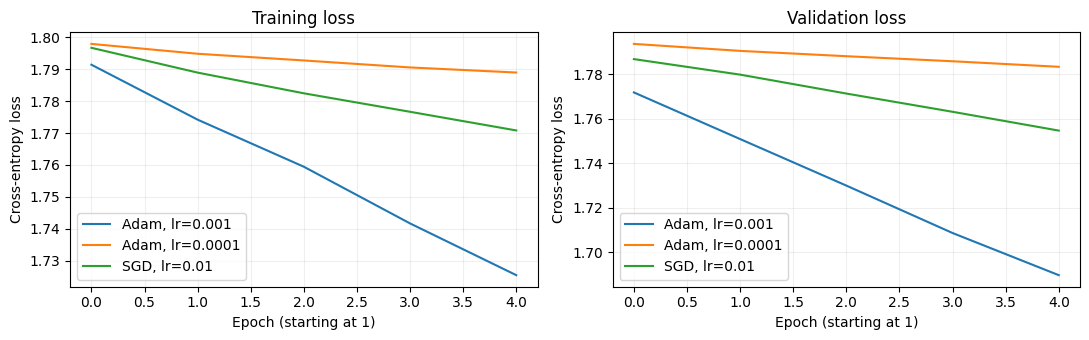

In [20]:
# Independent experiment: does not change the main comparison models.
RUN_OPTIMIZER_EXPERIMENT = True
OPT_EXPERIMENT_EPOCHS = 5

if RUN_OPTIMIZER_EXPERIMENT:
    configurations = [('Adam, lr=0.001', 'Adam', 1e-3),
                      ('Adam, lr=0.0001', 'Adam', 1e-4),
                      ('SGD, lr=0.01', 'SGD', 1e-2)]
    torch.manual_seed(SEED)
    reference_weights = copy.deepcopy(CompactCNN().state_dict())
    optimization_histories = {}
    for title, opt_name, lr in configurations:
        net = CompactCNN().to(device)
        net.load_state_dict(reference_weights)
        opt = (torch.optim.Adam(net.parameters(), lr=lr) if opt_name == 'Adam'
               else torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9))
        hist = []
        for epoch in range(OPT_EXPERIMENT_EPOCHS):
            net.train(); total_loss=0.; count=0
            for xb,yb in s_train:
                xb,yb=xb.to(device),yb.to(device)
                opt.zero_grad(set_to_none=True)
                loss=nn.CrossEntropyLoss()(net(xb),yb)
                loss.backward(); opt.step()
                total_loss += loss.item()*len(yb); count+=len(yb)
            metrics = evaluate(net,s_val)
            hist.append({'train_loss':total_loss/count,'val_loss':metrics['loss'],
                         'val_accuracy':metrics['accuracy']})
        optimization_histories[title]=hist
        print(title,'final validation accuracy:',f'{hist[-1]["val_accuracy"]:.1%}')
    fig, axes=plt.subplots(1,2,figsize=(11,3.5))
    for title, hist in optimization_histories.items():
        axes[0].plot([h['train_loss'] for h in hist],label=title)
        axes[1].plot([h['val_loss'] for h in hist],label=title)
    for ax,name in zip(axes,['Training loss','Validation loss']):
        ax.set(xlabel='Epoch (starting at 1)',ylabel='Cross-entropy loss',title=name)
        ax.legend();ax.grid(alpha=.2)
    plt.tight_layout();plt.show()

### Early stopping: use validation results, not training accuracy

A practical rule is to remember the model with the best validation score. If validation performance fails to improve for several epochs (*patience*), stop training and restore that checkpoint. Our existing `fit()` function already **restores the checkpoint with the highest validation accuracy**, but it still runs all requested epochs; it is *model checkpointing*, not early stopping.

For an experiment, modify `fit()` to track the number of epochs since the last improvement. When it reaches `patience=3`, break out of the epoch loop. Keep the original function intact for the model comparison unless you apply the same early-stopping rule to every candidate.

**Before moving on:** Explain in your own words the difference between loss and accuracy, the purpose of backpropagation, why `optimizer.step()` is needed, and why the validation set matters.

## 5. Experiment: two CNNs trained from scratch

Keep the training/validation split, optimizer and epoch budget the same to make the comparison interpretable. The deeper model has more parameters and more regularization; higher capacity does not guarantee better generalization.

**Student tasks:** predict which model wins; run both; identify the larger training–validation gap; explain whether either model appears to underfit.


Training Compact CNN
Epoch 1/4: train acc 0.176, val acc 0.200, val loss 1.770
Epoch 2/4: train acc 0.212, val acc 0.281, val loss 1.752
Epoch 3/4: train acc 0.229, val acc 0.263, val loss 1.740
Epoch 4/4: train acc 0.227, val acc 0.292, val loss 1.725
Compact CNN scratch validation accuracy: 29.2%


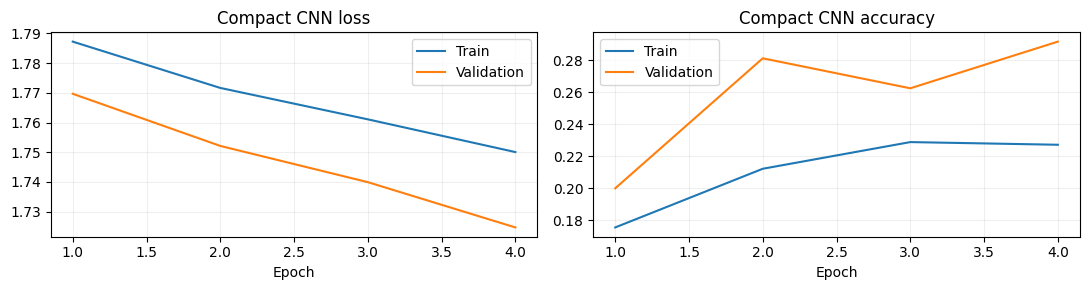


Training Deep CNN
Epoch 1/4: train acc 0.368, val acc 0.350, val loss 1.618
Epoch 2/4: train acc 0.518, val acc 0.429, val loss 1.413
Epoch 3/4: train acc 0.572, val acc 0.458, val loss 1.269
Epoch 4/4: train acc 0.598, val acc 0.415, val loss 1.506
Deep CNN scratch validation accuracy: 45.8%


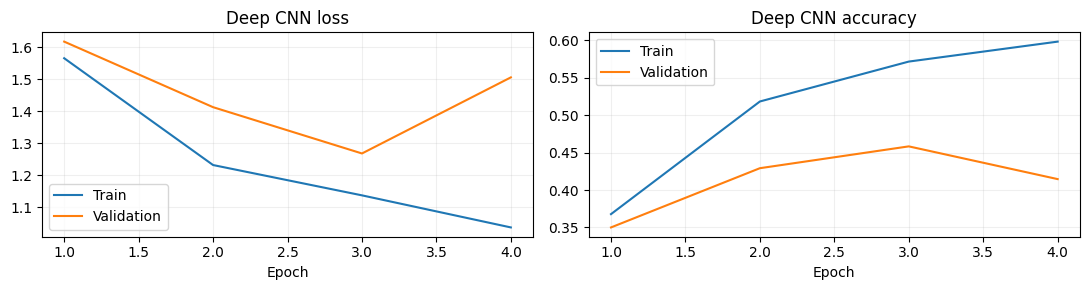

In [21]:
for name,cls in [('Compact CNN',CompactCNN),('Deep CNN',DeepCNN)]:
    print('\nTraining',name)
    net=cls().to(device)
    hist,seconds=fit(net,s_train,s_val,epochs=SCRATCH_EPOCHS,lr=1e-3)
    trained[name]=net
    record(name,'scratch',net,s_val,seconds)
    plot_history(hist,name)

### Architecture investigation

Change **one** variable at a time (e.g., `Dropout(.3)` to `.5`, or the number of convolutional filters). Reinitialize and retrain the affected architecture. Report the change, predicted effect, observed effect, and whether the comparison was controlled. Do not assume a single short run proves one design is always superior.

## 6. Pretrained CNNs: baseline, feature extraction and fine-tuning

**Pretraining:** ResNet18 and MobileNetV3-Small were trained on ImageNet's 1,000 classes. They have learned useful visual features before seeing our six-category vehicle dataset.

**Stage 0 — original weights, no training:** Their 1,000-class output is *not* directly a six-class prediction. To make a legitimate no-adaptation baseline, we sum the softmax probabilities of a small set of **semantically related ImageNet labels** for each of our six categories. Some categories have no good equivalent, so this is an illustrative and imperfect zero-shot proxy, not a fair upper bound.

**Stage 1 — feature extraction:** Replace the final classifier with a new six-class head, freeze the backbone, train only the head. This is *not full fine-tuning*.

**Stage 2 — partial fine-tuning:** Unfreeze the final feature block and train it together with the head at a lower learning rate. This adapts high-level features to our data.

For both architectures we will compare validation accuracy across stages. Use the same pretrained weights, data and training budget. Pretrained models need a larger resized input; the resize cannot invent missing image details.

[Official ResNet18 weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html) · [Official MobileNetV3-Small weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html)

In [22]:
MODEL_SPECS={
    'ResNet18': (models.resnet18, models.ResNet18_Weights.DEFAULT),
    'MobileNetV3-Small': (models.mobilenet_v3_small, models.MobileNet_V3_Small_Weights.DEFAULT)
}

def make_pretrained(name):
    constructor,weights=MODEL_SPECS[name]
    return constructor(weights=weights).to(device), weights

# Inspect available ImageNet category names; these are NOT the same as our target labels.
for name,(_,weights) in MODEL_SPECS.items():
    categories=weights.meta['categories']
    print(name,'ImageNet categories:',len(categories),'| examples:',categories[:6])

ResNet18 ImageNet categories: 1000 | examples: ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray']
MobileNetV3-Small ImageNet categories: 1000 | examples: ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray']


### Stage 0: test the original ImageNet classifier without training

We first display original ImageNet predictions on vehicle photos. This is a useful way to see what pretraining has already learned without claiming the output is one of our six classes. The classifier may say `sports car`, `minibus`, or something unrelated.

Next we use a **transparent proxy mapping** from ImageNet class names to our labels. It will not cover every class and may give zero scores for some categories. We report the *coverage* so students do not confuse this baseline with genuine six-class accuracy. The mapping is exploratory and should not be used to choose the final winner.

In [23]:
# A small illustrative semantic bridge; print available matches before using it.
PROXY_TERMS={
 'bicycle':['bicycle-built-for-two','mountain bike'],
 'bus':['minibus','school bus','trolleybus'],
 'motorcycle':['moped'],
 'pickup_truck':['pickup','tow truck'],
 'train':['electric locomotive','steam locomotive'],
 'streetcar':['streetcar']
}
original_models={}
for name in MODEL_SPECS:
    net,weights=make_pretrained(name);net.eval();original_models[name]=net
    categories=weights.meta['categories']
    matched={target:[categories.index(term) for term in terms if term in categories] for target,terms in PROXY_TERMS.items()}
    print('\n',name,'matched labels:',{k:[categories[i] for i in v] for k,v in matched.items()})
    images,truth=next(iter(p_val));images=images.to(device)
    with torch.no_grad(): logits=net(images);probs=logits.softmax(1)
    for j in range(min(5,len(truth))):
        top=probs[j].topk(3).indices.cpu().tolist()
        print('Target:',CLASS_NAMES[truth[j]],'| ImageNet top-3:',[categories[i] for i in top])
    # Note: no meaningful proxy score when classes lack a corresponding ImageNet label.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 160MB/s]



 ResNet18 matched labels: {'bicycle': ['bicycle-built-for-two', 'mountain bike'], 'bus': ['minibus', 'school bus', 'trolleybus'], 'motorcycle': ['moped'], 'pickup_truck': ['pickup', 'tow truck'], 'train': ['electric locomotive', 'steam locomotive'], 'streetcar': ['streetcar']}
Target: bicycle | ImageNet top-3: ['can opener', 'reel', 'revolver']
Target: bicycle | ImageNet top-3: ['bicycle-built-for-two', 'bluetick', 'black-and-tan coonhound']
Target: bicycle | ImageNet top-3: ['thresher', 'magnetic compass', 'fire screen']
Target: bicycle | ImageNet top-3: ['stethoscope', 'magnetic compass', 'wall clock']
Target: bicycle | ImageNet top-3: ['chain saw', 'thresher', 'oil filter']
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 95.4MB/s]


 MobileNetV3-Small matched labels: {'bicycle': ['bicycle-built-for-two', 'mountain bike'], 'bus': ['minibus', 'school bus', 'trolleybus'], 'motorcycle': ['moped'], 'pickup_truck': ['pickup', 'tow truck'], 'train': ['electric locomotive', 'steam locomotive'], 'streetcar': ['streetcar']}


Target: bicycle | ImageNet top-3: ['reel', 'whistle', 'muzzle']
Target: bicycle | ImageNet top-3: ['mountain bike', 'bicycle-built-for-two', 'unicycle']
Target: bicycle | ImageNet top-3: ['table lamp', 'plate rack', 'hourglass']
Target: bicycle | ImageNet top-3: ['loupe', 'nipple', 'Petri dish']
Target: bicycle | ImageNet top-3: ['moped', 'milk can', 'Petri dish']


### Stage 1: train only the new classification head

We replace the ImageNet head with six output neurons. At initialization this new layer is random, so evaluating it before training is not a valid measure of pretrained recognition. Freeze the backbone (`requires_grad=False`) and optimize only the new head. This typically trains quickly and is useful when data or GPU time is limited.

**Prediction:** Will the frozen-feature models outperform both scratch CNNs? Why might they not?


Head-only training: ResNet18 trainable parameters: 3078
Epoch 1/2: train acc 0.384, val acc 0.629, val loss 1.161
Epoch 2/2: train acc 0.666, val acc 0.706, val loss 0.934
ResNet18 head only validation accuracy: 70.6%


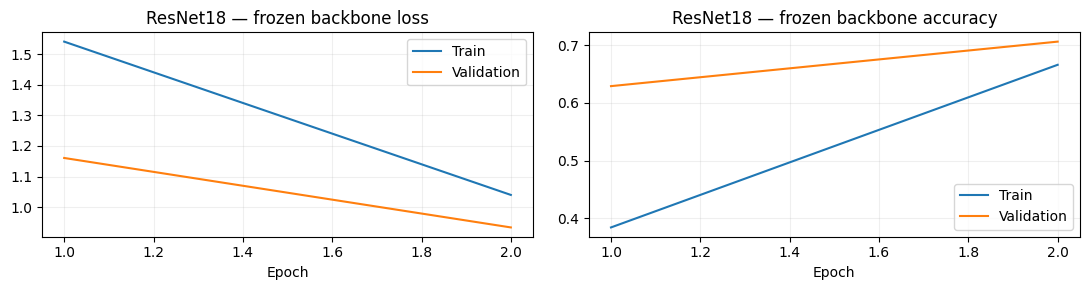


Head-only training: MobileNetV3-Small trainable parameters: 6150
Epoch 1/2: train acc 0.461, val acc 0.594, val loss 1.095
Epoch 2/2: train acc 0.709, val acc 0.644, val loss 0.938
MobileNetV3-Small head only validation accuracy: 64.4%


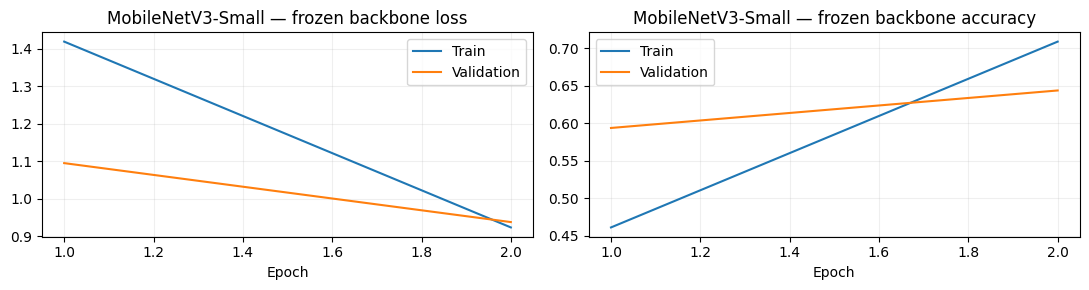

In [24]:
def replace_head_and_freeze(net,name):
    for p in net.parameters(): p.requires_grad=False
    if name=='ResNet18':
        in_features=net.fc.in_features
        net.fc=nn.Linear(in_features,len(CLASS_NAMES))
    else:
        in_features=net.classifier[-1].in_features
        net.classifier[-1]=nn.Linear(in_features,len(CLASS_NAMES))
    return net.to(device)

for name in MODEL_SPECS:
    net=replace_head_and_freeze(original_models[name],name)
    print('\nHead-only training:',name,'trainable parameters:',sum(p.numel() for p in net.parameters() if p.requires_grad))
    hist,seconds=fit(net,p_train,p_val,epochs=HEAD_EPOCHS,lr=1e-3,trainable_only=True)
    trained[name+' (head only)']=copy.deepcopy(net).cpu()
    record(name,'head only',net,p_val,seconds)
    plot_history(hist,name+' — frozen backbone')

### Stage 2: fine-tune the last feature block

Now unfreeze the final convolutional block and continue training from the **head-only checkpoint**. We keep earlier layers frozen to reduce compute and preserve lower-level features. The learning rate is smaller because we want to adjust useful pretrained features gently.

**Important detail:** frozen batch-normalization statistics can still update when `model.train()` is called. The training helper below holds fully frozen batch-normalization layers in evaluation mode. This makes the experiment more controlled.


Fine-tuning: ResNet18 trainable parameters: 8396806
Epoch 1/2: train 0.773, validation 0.819
Epoch 2/2: train 0.932, validation 0.838
ResNet18 fine-tuned validation accuracy: 83.8%


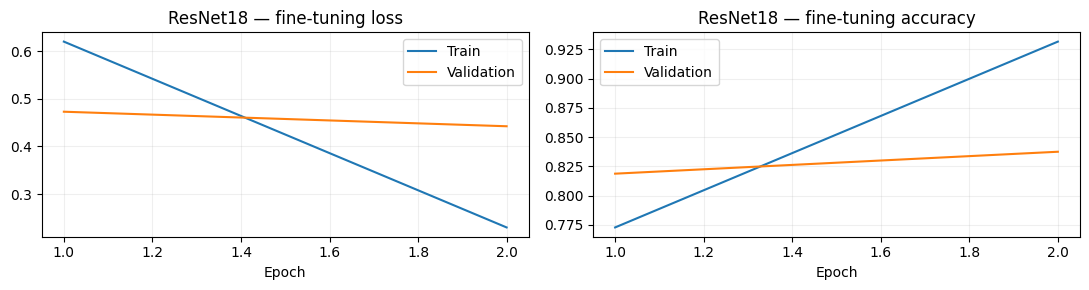


Fine-tuning: MobileNetV3-Small trainable parameters: 356694
Epoch 1/2: train 0.780, validation 0.688
Epoch 2/2: train 0.811, validation 0.710
MobileNetV3-Small fine-tuned validation accuracy: 71.0%


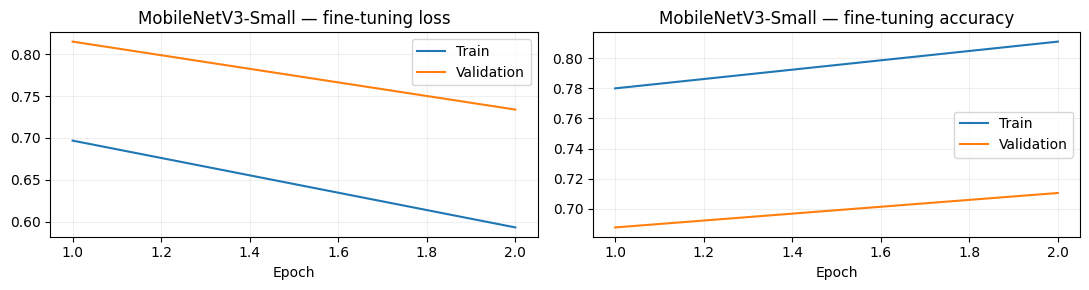

In [25]:
def enable_last_block(net,name):
    if name=='ResNet18':
        block=net.layer4
    else:
        block=net.features[-2:]
    for p in block.parameters(): p.requires_grad=True
    return net

# For this lab we adapt fit so fully frozen BN layers do not update running statistics.
def freeze_frozen_batchnorm(model):
    for module in model.modules():
        if isinstance(module,nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in module.parameters(recurse=False)):
                module.eval()

def fit_partial(model,train_loader,val_loader,epochs=2,lr=1e-4):
    model.to(device)
    optimizer=torch.optim.Adam([p for p in model.parameters() if p.requires_grad],lr=lr)
    criterion=nn.CrossEntropyLoss(); history=[];best=-1;best_state=None
    started=time.perf_counter()
    for epoch in range(epochs):
        model.train();freeze_frozen_batchnorm(model)
        correct=total=0; loss_total=0.
        for x,y in train_loader:
            x,y=x.to(device),y.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits=model(x);loss=criterion(logits,y);loss.backward();optimizer.step()
            correct+=(logits.argmax(1)==y).sum().item();total+=len(y);loss_total+=loss.item()*len(y)
        val=evaluate(model,val_loader)
        history.append({'epoch':epoch+1,'train_loss':loss_total/total,'train_accuracy':correct/total,'val_loss':val['loss'],'val_accuracy':val['accuracy']})
        print(f'Epoch {epoch+1}/{epochs}: train {correct/total:.3f}, validation {val["accuracy"]:.3f}')
        if val['accuracy']>best: best=val['accuracy'];best_state=copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return history,time.perf_counter()-started

for name in MODEL_SPECS:
    net=trained[name+' (head only)'].to(device)
    net=enable_last_block(net,name)
    print('\nFine-tuning:',name,'trainable parameters:',sum(p.numel() for p in net.parameters() if p.requires_grad))
    hist,seconds=fit_partial(net,p_train,p_val,epochs=FINETUNE_EPOCHS,lr=1e-4)
    trained[name+' (fine-tuned)']=copy.deepcopy(net).cpu()
    record(name,'fine-tuned',net,p_val,seconds)
    plot_history(hist,name+' — fine-tuning')

## 7. Compare results and select finalists

Use **validation accuracy** to select the strongest scratch CNN and the strongest pretrained model (head-only or fine-tuned). Keep the test set untouched until after selection. Remember that the pretrained models use higher-resolution *resized* inputs and had access to external ImageNet pretraining; the scratch models did not.

**Discussion:** Did fine-tuning help? Is a gain of 1–2 percentage points convincing on a small validation set? What would you change to make the comparison more reliable?

,model,stage,val_accuracy,val_loss,parameters,train_seconds
4,ResNet18,fine-tuned,0.837500,0.442360,11179590,6.3
5,MobileNetV3-Small,fine-tuned,0.710417,0.733943,1524006,6.2
2,ResNet18,head only,0.706250,0.933568,11179590,6.1
3,MobileNetV3-Small,head only,0.643750,0.938325,1524006,6.1
1,Deep CNN,scratch,0.458333,1.268665,288230,4.4
0,Compact CNN,scratch,0.291667,1.724682,5286,3.9


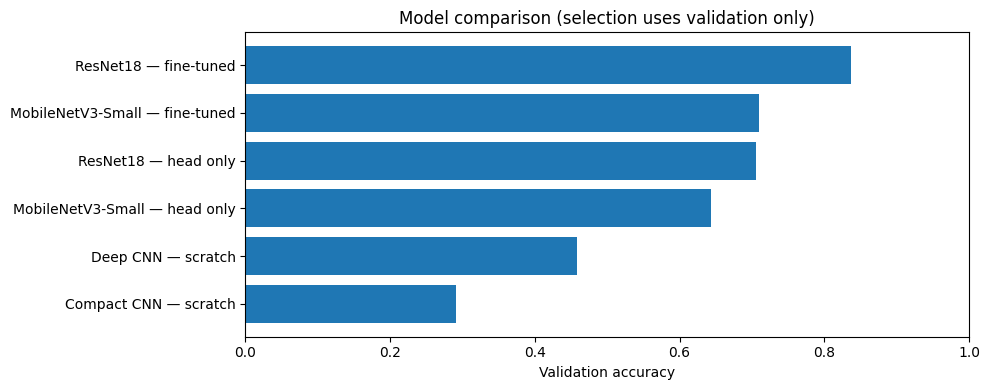

Best scratch: Deep CNN | Best pretrained: ResNet18 (fine-tuned)


In [26]:
comparison=pd.DataFrame(results).sort_values('val_accuracy',ascending=False)
display(comparison)
fig,ax=plt.subplots(figsize=(10,4))
labels=comparison['model']+' — '+comparison['stage']
ax.barh(labels,comparison.val_accuracy);ax.invert_yaxis();ax.set_xlim(0,1)
ax.set_xlabel('Validation accuracy');ax.set_title('Model comparison (selection uses validation only)')
plt.tight_layout();plt.show()
scratch_names=['Compact CNN','Deep CNN']
scratch_rows=comparison[comparison.model.isin(scratch_names)]
pre_rows=comparison[~comparison.model.isin(scratch_names)]
best_scratch=scratch_rows.iloc[0]['model']
best_pre_row=pre_rows.iloc[0]
best_pre=best_pre_row['model']+' ('+best_pre_row['stage']+')'
print('Best scratch:',best_scratch,'| Best pretrained:',best_pre)

### Final test-set evaluation

This is the first time the test set is used for scoring. Test-set results estimate generalization; do not repeatedly change hyperparameters based on the test score. Inspect the confusion matrix and a few errors for each finalist.


 Deep CNN test accuracy: 47.2%
              precision    recall  f1-score   support

     bicycle       0.54      0.85      0.66       100
         bus       0.58      0.15      0.24       100
  motorcycle       0.88      0.52      0.65       100
pickup_truck       0.47      0.47      0.47       100
       train       0.30      0.74      0.43       100
   streetcar       0.77      0.10      0.18       100

    accuracy                           0.47       600
   macro avg       0.59      0.47      0.44       600
weighted avg       0.59      0.47      0.44       600



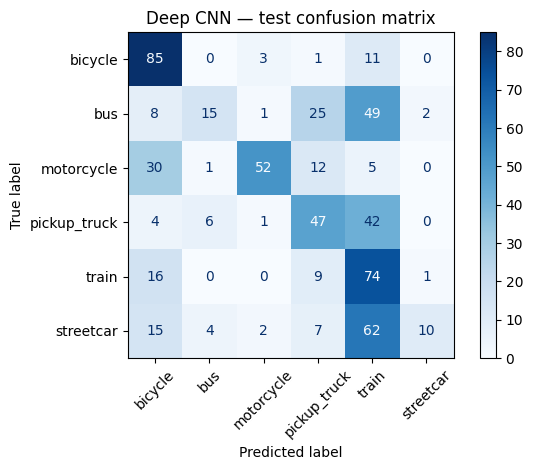


 ResNet18 (fine-tuned) test accuracy: 83.2%
              precision    recall  f1-score   support

     bicycle       0.96      0.89      0.92       100
         bus       0.81      0.65      0.72       100
  motorcycle       0.87      0.96      0.91       100
pickup_truck       0.90      0.85      0.88       100
       train       0.76      0.84      0.80       100
   streetcar       0.71      0.80      0.75       100

    accuracy                           0.83       600
   macro avg       0.84      0.83      0.83       600
weighted avg       0.84      0.83      0.83       600



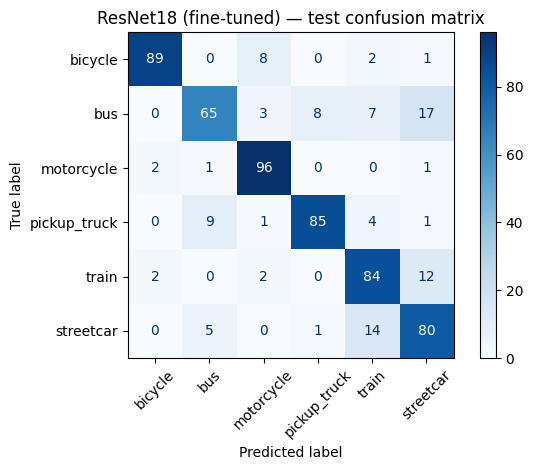

In [27]:
finalists=[(best_scratch,s_test),(best_pre,p_test)]
for name,loader in finalists:
    net=trained[name].to(device)
    scores,y_true,y_pred=evaluate(net,loader,return_predictions=True)
    print('\n',name,'test accuracy:',f'{scores["accuracy"]:.1%}')
    print(classification_report(y_true,y_pred,target_names=CLASS_NAMES,zero_division=0))
    cm=confusion_matrix(y_true,y_pred,labels=list(range(len(CLASS_NAMES))))
    ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(xticks_rotation=45,cmap='Blues',values_format='d')
    plt.title(name+' — test confusion matrix');plt.tight_layout();plt.show()

### Inspect model failures

Misclassified examples are often more educational than correct ones. Are they blurred, visually ambiguous, or too small? Does the model confuse visually similar classes? This code plots validation errors so that students can iterate without looking at the test set again.

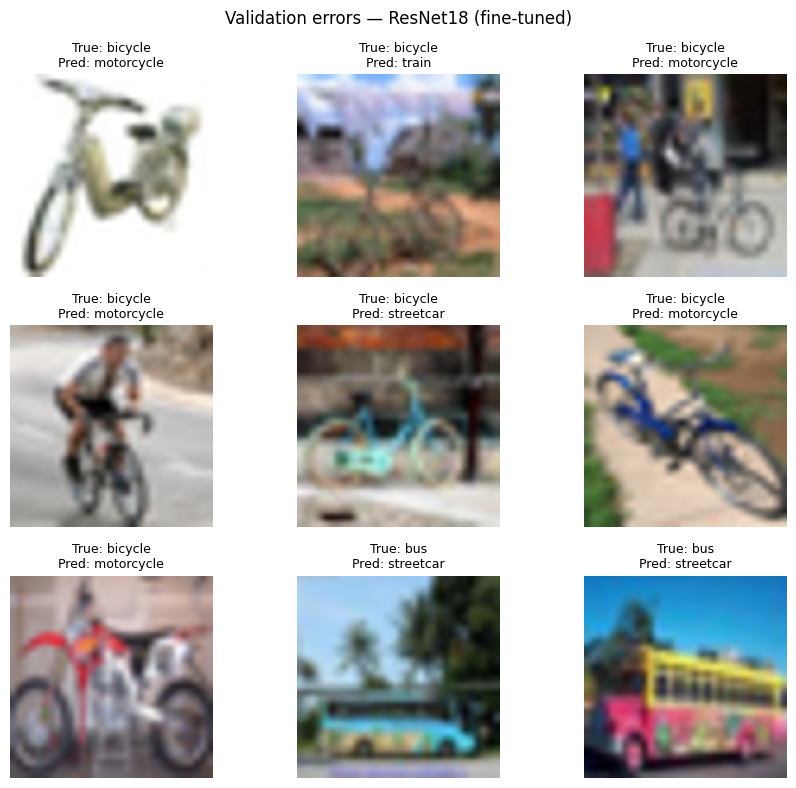

In [28]:
name=best_pre
net=trained[name].to(device)
score,truth,preds=evaluate(net,p_val,return_predictions=True)
wrong=np.flatnonzero(np.asarray(truth)!=np.asarray(preds))[:9]
fig,axes=plt.subplots(3,3,figsize=(9,8))
val_data=p_val.dataset
for ax in axes.flat:ax.axis('off')
for ax,i in zip(axes.flat,wrong):
    original_idx=val_data.indices[int(i)]
    img,_=raw_train[original_idx]
    ax.imshow(img.resize((160,160)));ax.set_title(f'True: {CLASS_NAMES[truth[i]]}\nPred: {CLASS_NAMES[preds[i]]}',fontsize=9)
plt.suptitle('Validation errors — '+name);plt.tight_layout();plt.show()

## 8. RNNs: learn from ordered observations

CNNs are designed for spatial information. RNNs handle **sequences**, where the order of observations matters. In a standard RNN, the hidden state is updated using the current input and previous hidden state. A GRU adds gates to control how much information to retain or update.

For a vehicle-related example, imagine a roadside sensor measuring traffic intensity over several intervals. The model receives a sequence and predicts whether traffic is **increasing** or **decreasing**. This is a synthetic learning exercise, not real traffic data. We compare a vanilla RNN and a GRU under the same training setup.

**Input shape:** `[batch, sequence_length, features]` when `batch_first=True`. Here features=1 (one sensor reading per interval).

**Questions:** Why would shuffling the time steps change the meaning? Why might a GRU help with longer sequences?

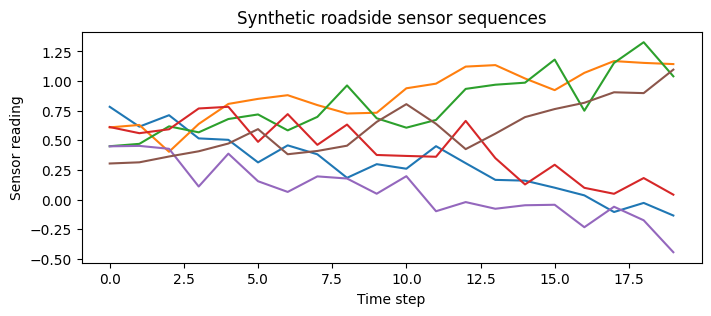

RNN final validation accuracy: 1.0
GRU final validation accuracy: 1.0


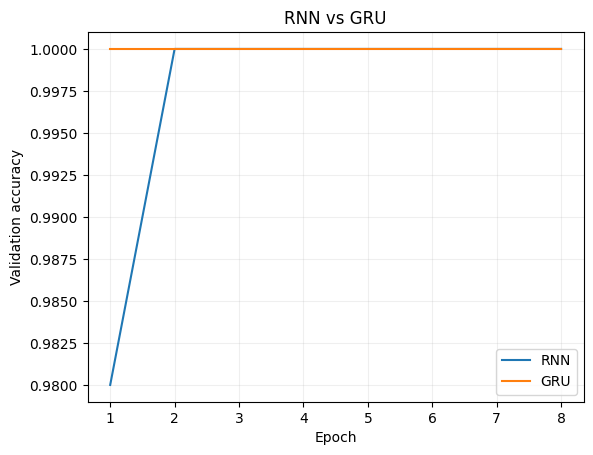

In [29]:
def make_traffic(n,steps=20,seed=0):
    rng=np.random.default_rng(seed)
    labels=rng.integers(0,2,size=n)
    x=[]
    for label in labels:
        slope=(.035 if label==1 else -.035)
        start=rng.uniform(.25,.75)
        seq=start+slope*np.arange(steps)+rng.normal(0,.12,size=steps)
        x.append(seq)
    return torch.tensor(np.array(x),dtype=torch.float32).unsqueeze(-1),torch.tensor(labels,dtype=torch.long)

seq_x,seq_y=make_traffic(1600,seed=SEED)
seq_x_val,seq_y_val=make_traffic(400,seed=SEED+1)
fig,ax=plt.subplots(figsize=(8,3))
for i in range(6): ax.plot(seq_x[i,:,0],label=['Decreasing','Increasing'][seq_y[i]])
ax.set_title('Synthetic roadside sensor sequences');ax.set_xlabel('Time step');ax.set_ylabel('Sensor reading');plt.show()

class TrafficRNN(nn.Module):
    def __init__(self,cell='RNN',hidden=24):
        super().__init__()
        self.recurrent=(nn.GRU if cell=='GRU' else nn.RNN)(input_size=1,hidden_size=hidden,batch_first=True)
        self.head=nn.Linear(hidden,2)
    def forward(self,x):
        _,hidden=self.recurrent(x)
        return self.head(hidden[-1])

def train_sequence(cell):
    net=TrafficRNN(cell).to(device)
    optim=torch.optim.Adam(net.parameters(),lr=.003)
    criterion=nn.CrossEntropyLoss()
    loader=DataLoader(torch.utils.data.TensorDataset(seq_x,seq_y),batch_size=64,shuffle=True)
    history=[]
    for epoch in range(8):
        net.train()
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            optim.zero_grad();loss=criterion(net(x),y);loss.backward();optim.step()
        net.eval()
        with torch.no_grad():
            accuracy=(net(seq_x_val.to(device)).argmax(1).cpu()==seq_y_val).float().mean().item()
        history.append(accuracy)
    return net,history

sequence_results={}
for cell in ['RNN','GRU']:
    net,hist=train_sequence(cell);sequence_results[cell]=hist
    print(cell,'final validation accuracy:',round(hist[-1],3))
    plt.plot(range(1,len(hist)+1),hist,label=cell)
plt.xlabel('Epoch');plt.ylabel('Validation accuracy');plt.title('RNN vs GRU');plt.legend();plt.grid(alpha=.2);plt.show()

### RNN experiment

Increase sequence length from 20 to 40 in both datasets, rerun training, and compare RNN/GRU performance. Alternatively, increase noise from `0.12` to `0.25`. Change **one factor at a time**. Explain whether the model learns an ordered trend or simply memorizes values.

**Connection to license plates:** A plate recognition system can turn an image into an ordered sequence of character features. A recurrent decoder (often with CTC loss) can then predict text, but that is a more advanced pipeline than the traffic sequence example.

### Further reading
- [PyTorch CNN classifier tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html)
- [PyTorch transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [PyTorch RNN API](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html)
- [PyTorch GRU API](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html)
- [CIFAR-100 dataset](https://www.cs.toronto.edu/~kriz/cifar.html)